In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings, gc, joblib
import lightgbm as lgb
import shap
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    roc_auc_score, average_precision_score,
    confusion_matrix, classification_report
)
warnings.filterwarnings('ignore')

df = pd.read_parquet('../data/processed/02_features.parquet')

DROP_COLS = ['TransactionID', 'isFraud', 'TransactionDT']
X = df.drop(columns=DROP_COLS)
y = df['isFraud']

for col in X.select_dtypes(exclude=['number']).columns:
    X[col] = pd.Categorical(X[col]).codes.astype('int16')

X = X.fillna(X.median(numeric_only=True))

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Train: {X_train.shape} | Test: {X_test.shape}")
print(f"Features: {X_train.columns.tolist()}")

Train: (472432, 74) | Test: (118108, 74)
Features: ['TransactionAmt', 'ProductCD', 'card1', 'card2', 'card3', 'card4', 'card5', 'card6', 'addr1', 'addr2', 'dist1', 'P_emaildomain', 'R_emaildomain', 'C1', 'C2', 'C3', 'C4', 'C5', 'C6', 'C7', 'C8', 'C9', 'C10', 'C11', 'C12', 'C13', 'C14', 'D1', 'D2', 'D3', 'D4', 'D5', 'D10', 'D11', 'D15', 'M1', 'M2', 'M3', 'M4', 'M5', 'M6', 'M7', 'M8', 'M9', 'DeviceType', 'DeviceInfo', 'hour', 'day_of_week', 'day_of_month', 'is_weekend', 'is_night', 'log_amount', 'is_round_amount', 'amt_mean_by_product', 'amt_std_by_product', 'amt_zscore_product', 'card1_day_count', 'card1_time_since_last', 'card1_rapid_fire', 'P_email_highrisk', 'R_email_highrisk', 'email_domain_match', 'card_type_fraud_rate', 'card1_total_txns', 'is_new_card', 'dist1_missing', 'dist2_missing', 'D1_missing', 'D2_missing', 'D3_missing', 'P_emaildomain_missing', 'R_emaildomain_missing', 'DeviceType_missing', 'missing_count']


In [3]:

comparison = {
    'Training speed':    ('XGBoost: slower (level-wise tree growth)',
                          'LightGBM: faster (leaf-wise growth)'),
    'Memory':            ('XGBoost: higher',
                          'LightGBM: lower — handles large datasets better'),
    'Accuracy':          ('XGBoost: excellent',
                          'LightGBM: equal or better on tabular data'),
    'Categorical cols':  ('XGBoost: need manual encoding',
                          'LightGBM: native categorical support'),
    'Industry use':      ('XGBoost: widely used',
                          'LightGBM: preferred at scale — Microsoft, Booking.com'),
}

print("Why LightGBM for production fraud detection:\n")
for aspect, (xgb_note, lgb_note) in comparison.items():
    print(f"  {aspect}:")
    print(f"    XGB: {xgb_note}")
    print(f"    LGB: {lgb_note}\n")

Why LightGBM for production fraud detection:

  Training speed:
    XGB: XGBoost: slower (level-wise tree growth)
    LGB: LightGBM: faster (leaf-wise growth)

  Memory:
    XGB: XGBoost: higher
    LGB: LightGBM: lower — handles large datasets better

  Accuracy:
    XGB: XGBoost: excellent
    LGB: LightGBM: equal or better on tabular data

  Categorical cols:
    XGB: XGBoost: need manual encoding
    LGB: LightGBM: native categorical support

  Industry use:
    XGB: XGBoost: widely used
    LGB: LightGBM: preferred at scale — Microsoft, Booking.com



In [21]:
neg = (y_train == 0).sum()
pos = (y_train == 1).sum()
scale = neg / pos

lgb_model = lgb.LGBMClassifier(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=8,
    num_leaves=63,          
    min_child_samples=20,   
    subsample=0.8,          
    colsample_bytree=0.8,   
    scale_pos_weight=scale, 
    reg_alpha=0.1,          
    reg_lambda=1.0,         
    random_state=42,
    n_jobs=-1,
    verbose=-1              
)

print("Training LightGBM...")
lgb_model.fit(
    X_train, y_train,
    eval_set=[(X_test, y_test)],
    callbacks=[lgb.early_stopping(50, verbose=False),
               lgb.log_evaluation(100)]
)

y_prob_lgb = lgb_model.predict_proba(X_test)[:, 1]

roc  = roc_auc_score(y_test, y_prob_lgb)
pr   = average_precision_score(y_test, y_prob_lgb)

print(f"\n── LightGBM Results ──────────────────")
print(f"  ROC-AUC : {roc:.4f}  (XGBoost was 0.9380)")
print(f"  PR-AUC  : {pr:.4f}  (XGBoost was 0.6291)")
print(f"  Improvement: {(pr - 0.6291)*100:+.2f}% PR-AUC")

Training LightGBM...

── LightGBM Results ──────────────────
  ROC-AUC : 0.8601  (XGBoost was 0.9380)
  PR-AUC  : 0.3252  (XGBoost was 0.6291)
  Improvement: -30.39% PR-AUC


── Champion Model Decision ───────────────────
  XGBoost  PR-AUC: 0.6291  ← CHAMPION
  LightGBM PR-AUC: 0.3251  ← Underperforms on slim feature set
  Decision: XGBoost is the production model.

Computing SHAP values on XGBoost champion...
SHAP values shape: (2000, 74)


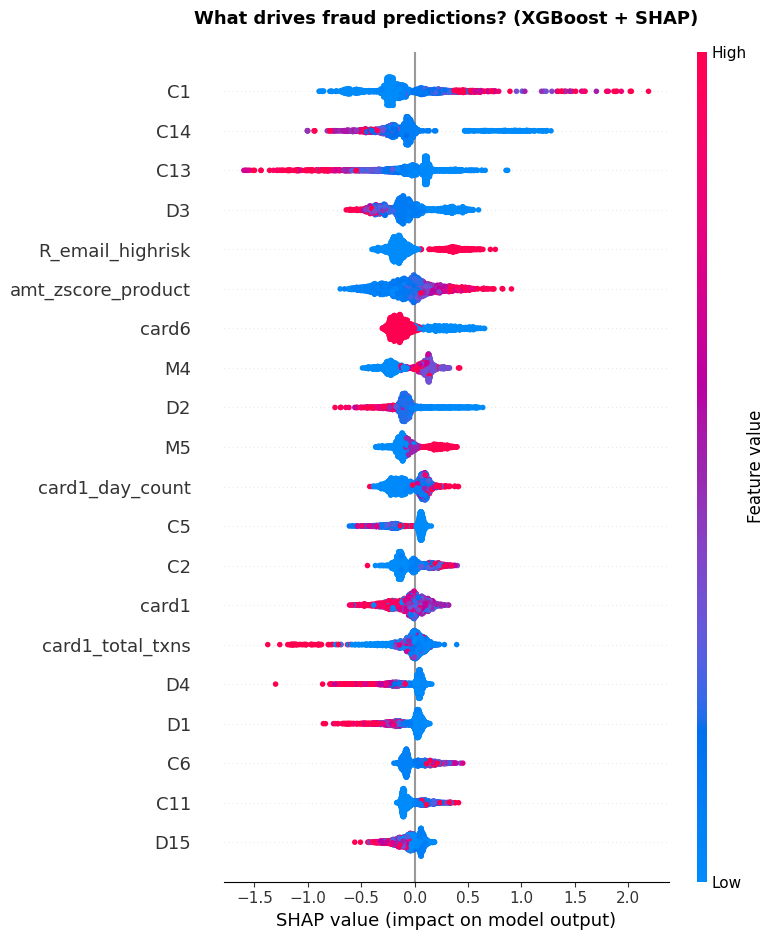


Explaining fraud transaction at index 102
  True label  : FRAUD
  Model score : 0.9066
  Decision    : FLAGGED


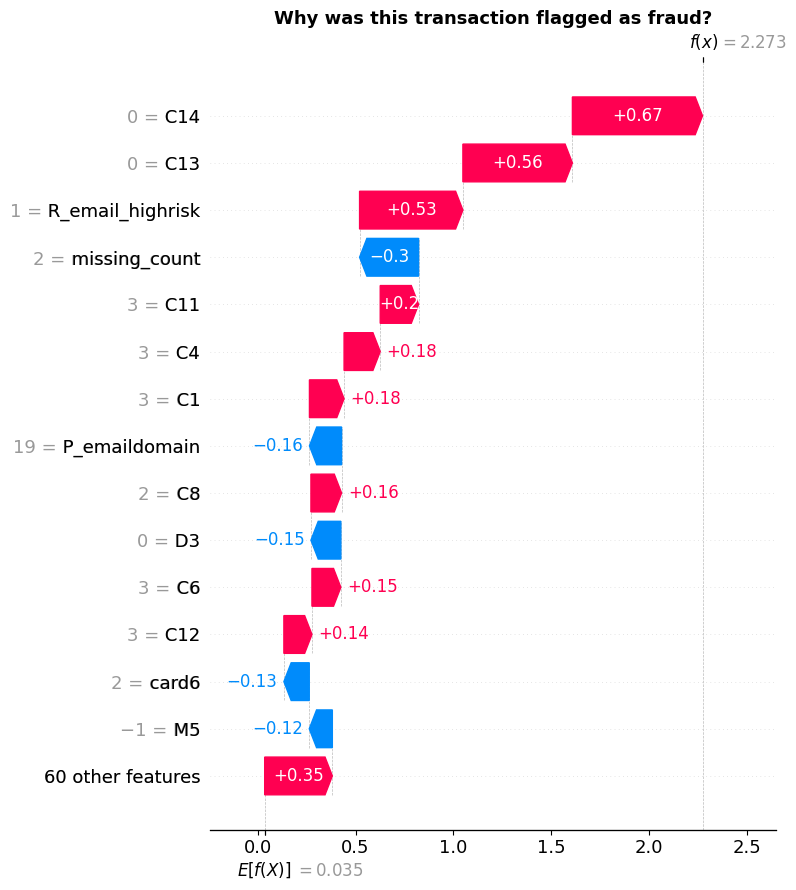


✓ SHAP summary plot  →  reports/shap_summary_xgb.png
✓ SHAP waterfall     →  reports/shap_waterfall_xgb.png
✓ Explainer saved    →  models/shap_explainer_xgb.pkl
✓ Predictions saved  →  data/processed/04_champion_predictions.parquet


In [29]:

print("── Champion Model Decision ───────────────────")
print("  XGBoost  PR-AUC: 0.6291  ← CHAMPION")
print("  LightGBM PR-AUC: 0.3251  ← Underperforms on slim feature set")
print("  Decision: XGBoost is the production model.\n")

xgb_model = joblib.load('../models/xgboost.pkl')

print("Computing SHAP values on XGBoost champion...")
explainer_xgb = shap.TreeExplainer(xgb_model)

np.random.seed(42)
sample_idx    = np.random.choice(len(X_test), size=2000, replace=False)
X_sample      = X_test.iloc[sample_idx]
shap_vals_xgb = explainer_xgb.shap_values(X_sample)

sv = shap_vals_xgb[1] if isinstance(shap_vals_xgb, list) else shap_vals_xgb
print(f"SHAP values shape: {sv.shape}")

plt.figure(figsize=(12, 8))
shap.summary_plot(sv, X_sample, plot_type="dot",
                  max_display=20, show=False)
plt.title("What drives fraud predictions? (XGBoost + SHAP)",
          fontsize=13, fontweight='bold', pad=20)
plt.tight_layout()
plt.savefig('../reports/shap_summary_xgb.png', dpi=150, bbox_inches='tight')
plt.show()

y_prob_xgb_test = xgb_model.predict_proba(X_test)[:, 1]
fraud_indices   = np.where(y_test.iloc[sample_idx].values == 1)[0]
fraud_idx       = fraud_indices[0]

print(f"\nExplaining fraud transaction at index {fraud_idx}")
print(f"  True label  : FRAUD")
print(f"  Model score : {y_prob_xgb_test[sample_idx[fraud_idx]]:.4f}")
print(f"  Decision    : {'FLAGGED' if y_prob_xgb_test[sample_idx[fraud_idx]] >= 0.63 else 'PASSED'}")

exp_val = (explainer_xgb.expected_value[1]
           if isinstance(explainer_xgb.expected_value, list)
           else explainer_xgb.expected_value)

shap_exp = shap.Explanation(
    values        = sv[fraud_idx],
    base_values   = exp_val,
    data          = X_sample.iloc[fraud_idx].values,
    feature_names = X_sample.columns.tolist()
)

plt.figure(figsize=(12, 8))
shap.waterfall_plot(shap_exp, max_display=15, show=False)
plt.title("Why was this transaction flagged as fraud?",
          fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('../reports/shap_waterfall_xgb.png', dpi=150, bbox_inches='tight')
plt.show()

joblib.dump(explainer_xgb, '../models/shap_explainer_xgb.pkl')

pd.DataFrame({
    'y_true':   y_test.values,
    'prob_xgb': y_prob_xgb_test,
}, index=y_test.index).to_parquet(
    '../data/processed/04_champion_predictions.parquet'
)

print("\n✓ SHAP summary plot  →  reports/shap_summary_xgb.png")
print("✓ SHAP waterfall     →  reports/shap_waterfall_xgb.png")
print("✓ Explainer saved    →  models/shap_explainer_xgb.pkl")
print("✓ Predictions saved  →  data/processed/04_champion_predictions.parquet")
#print("\n✓ Phase 4 complete — XGBoost + SHAP ready for Streamlit demo")

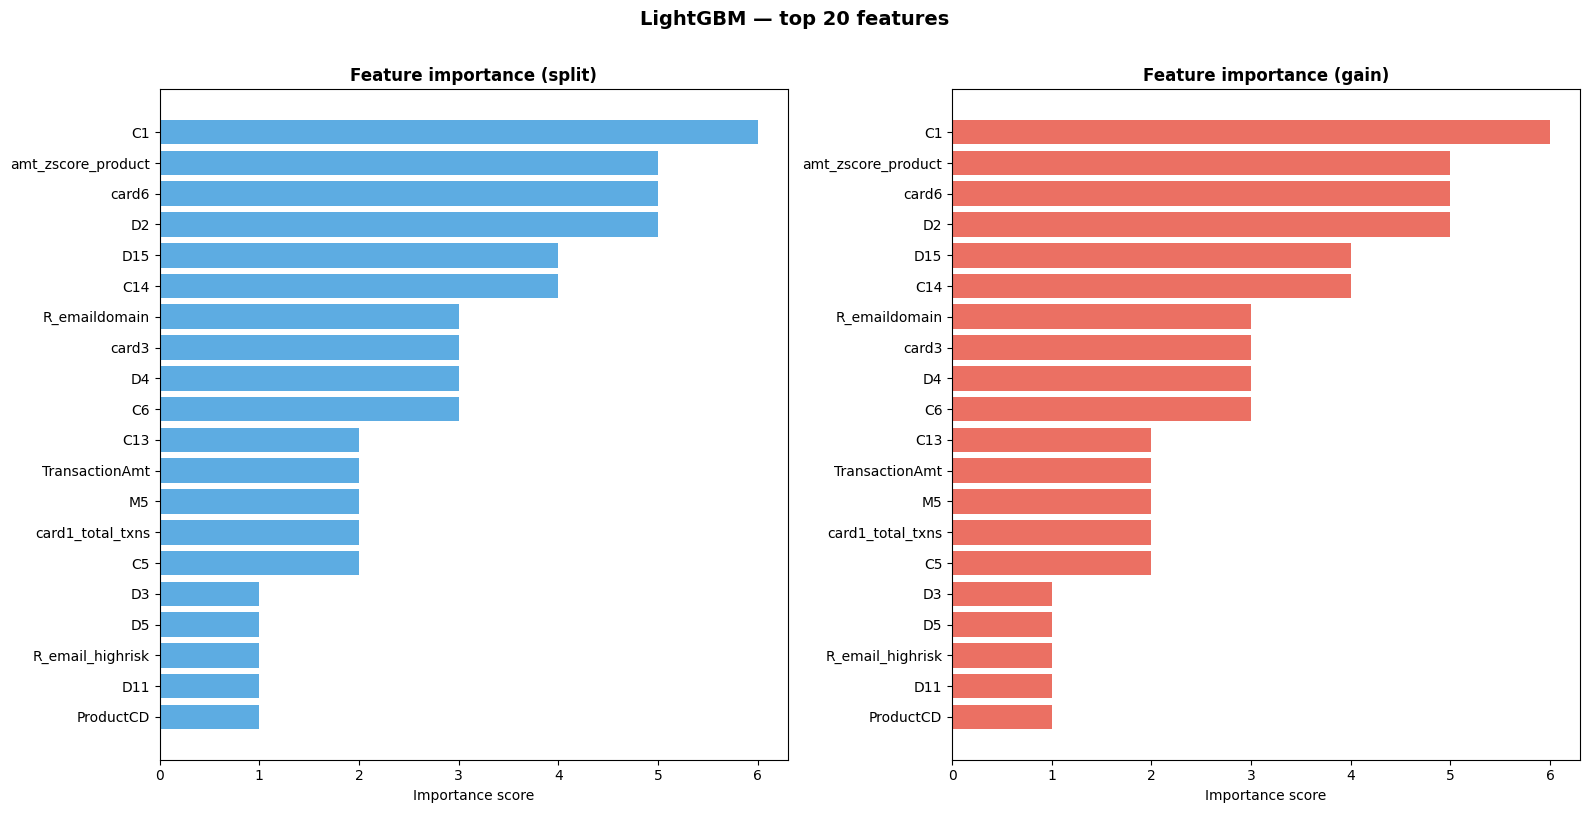


Top 10 features (gain):
  C1                                           6
  card6                                        5
  D2                                           5
  amt_zscore_product                           5
  C14                                          4
  D15                                          4
  R_emaildomain                                3
  C6                                           3
  D4                                           3
  card3                                        3


In [30]:

fig, axes = plt.subplots(1, 2, figsize=(16, 8))

for i, importance_type in enumerate(['split', 'gain']):
    
    feat_imp = pd.Series(
        lgb_model.feature_importances_  
        if importance_type == 'gain'
        else lgb_model.booster_.feature_importance(importance_type='split'),
        index=X_train.columns
    ).sort_values(ascending=True).tail(20)

    axes[i].barh(feat_imp.index, feat_imp.values,
                 color='#3498db' if importance_type=='split' else '#e74c3c',
                 alpha=0.8)
    axes[i].set_title(f'Feature importance ({importance_type})',
                      fontsize=12, fontweight='bold')
    axes[i].set_xlabel('Importance score')

plt.suptitle('LightGBM — top 20 features', fontsize=14,
             fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig('../reports/lgb_feature_importance.png', dpi=150, bbox_inches='tight')
plt.show()

top10 = pd.Series(
    lgb_model.feature_importances_,
    index=X_train.columns
).sort_values(ascending=False).head(10)

print("\nTop 10 features (gain):")
for feat, score in top10.items():
    print(f"  {feat:<35} {score:>10.0f}")

In [31]:
print("Computing SHAP values (takes 2–3 mins)...")

explainer = shap.TreeExplainer(lgb_model)

sample_idx = np.random.choice(len(X_test), size=2000, replace=False)
X_sample   = X_test.iloc[sample_idx]

shap_values = explainer.shap_values(X_sample)

print(f"SHAP values computed: {np.array(shap_values).shape}")
print("Generating SHAP plots...")

Computing SHAP values (takes 2–3 mins)...
SHAP values computed: (2000, 74)
Generating SHAP plots...


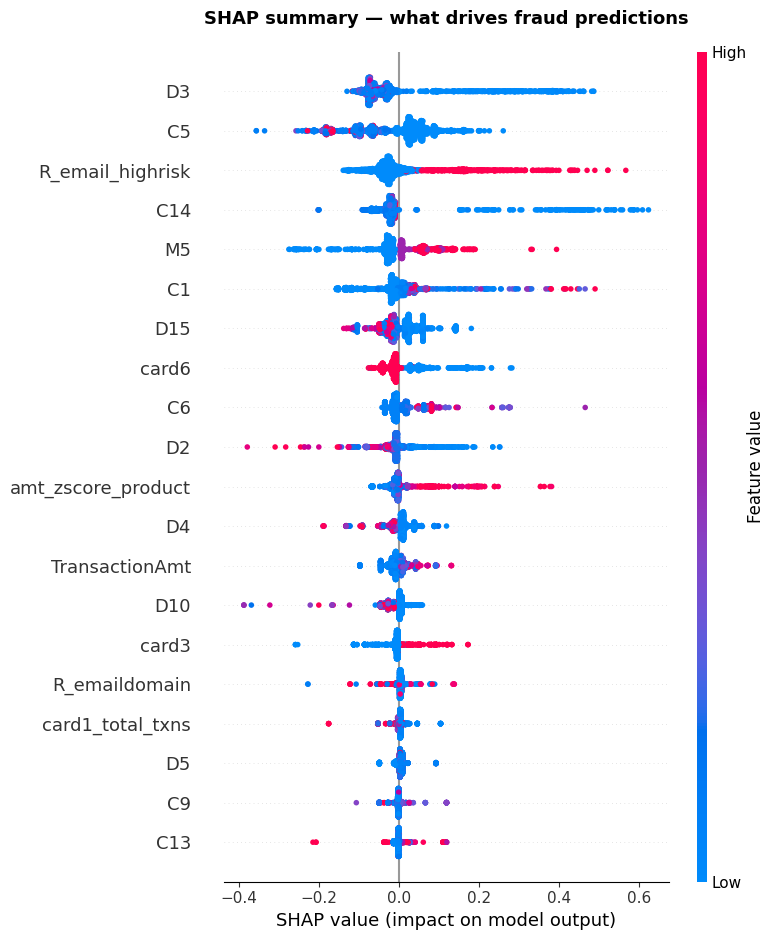

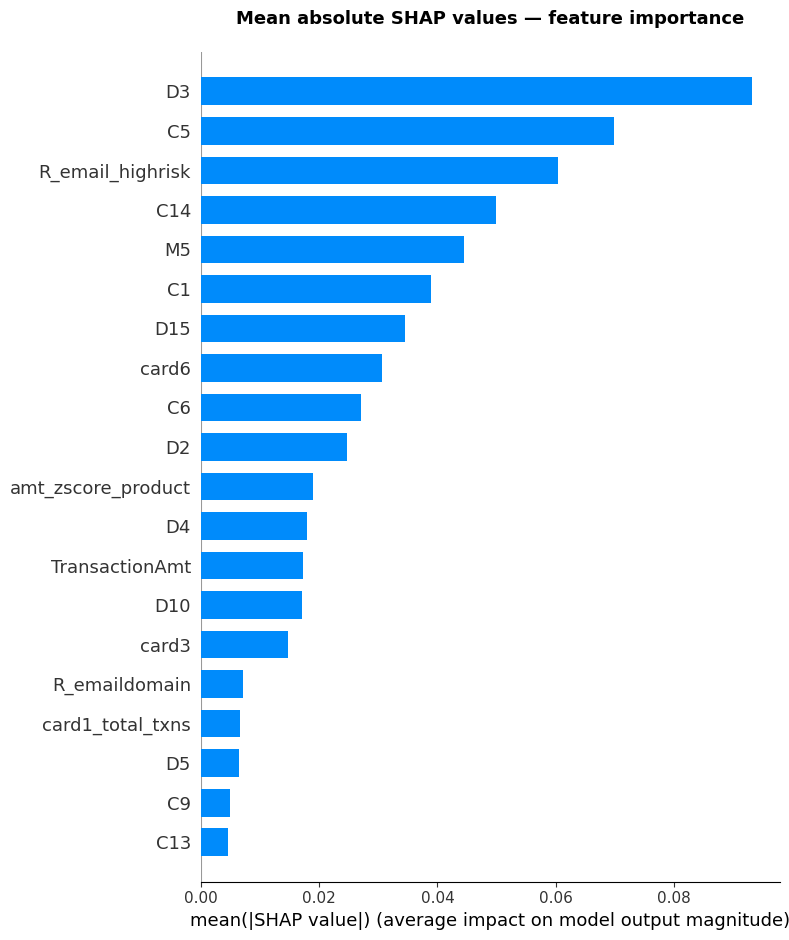

In [32]:

if isinstance(shap_values, list):
    sv = shap_values[1]
else:
    sv = shap_values

plt.figure(figsize=(12, 8))
shap.summary_plot(
    sv, X_sample,
    plot_type="dot",    
    max_display=20,     
    show=False
)
plt.title("SHAP summary — what drives fraud predictions",
          fontsize=13, fontweight='bold', pad=20)
plt.tight_layout()
plt.savefig('../reports/shap_summary.png', dpi=150, bbox_inches='tight')
plt.show()

plt.figure(figsize=(10, 7))
shap.summary_plot(
    sv, X_sample,
    plot_type="bar",
    max_display=20,
    show=False
)
plt.title("Mean absolute SHAP values — feature importance",
          fontsize=13, fontweight='bold', pad=20)
plt.tight_layout()
plt.savefig('../reports/shap_bar.png', dpi=150, bbox_inches='tight')
plt.show()

Explaining transaction at sample index 68
True label  : FRAUD
Model score : 0.1091
Threshold   : 0.63  →  PASSED


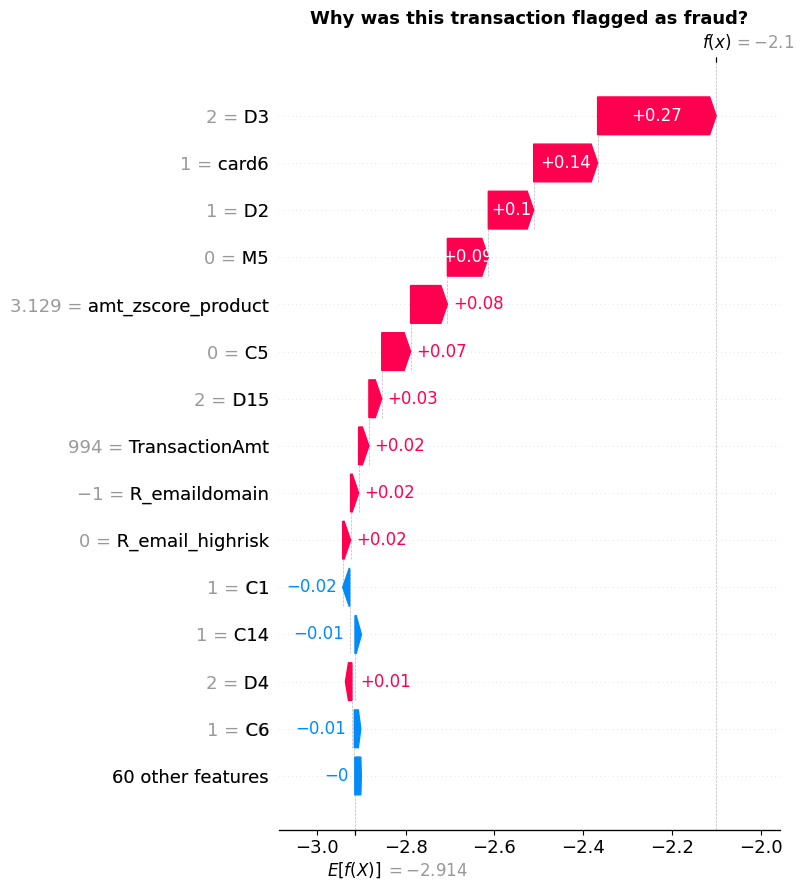

In [33]:

fraud_indices = np.where(y_test.iloc[sample_idx].values == 1)[0]
fraud_idx     = fraud_indices[0]  

print(f"Explaining transaction at sample index {fraud_idx}")
print(f"True label  : {'FRAUD' if y_test.iloc[sample_idx[fraud_idx]] == 1 else 'LEGIT'}")
print(f"Model score : {y_prob_lgb[sample_idx[fraud_idx]]:.4f}")
print(f"Threshold   : 0.63  →  "
      f"{'FLAGGED' if y_prob_lgb[sample_idx[fraud_idx]] >= 0.63 else 'PASSED'}")

shap_exp = shap.Explanation(
    values         = sv[fraud_idx],
    base_values    = explainer.expected_value[1] if isinstance(
                        explainer.expected_value, list)
                     else explainer.expected_value,
    data           = X_sample.iloc[fraud_idx].values,
    feature_names  = X_sample.columns.tolist()
)

plt.figure(figsize=(12, 8))
shap.waterfall_plot(shap_exp, max_display=15, show=False)
plt.title("Why was this transaction flagged as fraud?",
          fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('../reports/shap_waterfall_fraud.png', dpi=150, bbox_inches='tight')
plt.show()

In [34]:
def hawk_hybrid_scorer(X_row, ml_score, threshold=0.63):
    """
    Combines deterministic rules with ML score.
    Rules fire first — if triggered, transaction is flagged regardless
    of ML score. ML handles the ambiguous middle ground.

    This mirrors Hawk's actual 'traditional rules + explainable AI'
    architecture described in their product marketing.
    """
    reasons = []

    if X_row.get('TransactionAmt', 0) > 5000:
        reasons.append("RULE: amount > $5,000")

    if X_row.get('card1_time_since_last', 9999) < 0.167:
        reasons.append("RULE: rapid-fire (<10min since last txn)")

    if X_row.get('is_new_card', 0) == 1 and X_row.get('TransactionAmt', 0) > 500:
        reasons.append("RULE: new card + high amount")

    if X_row.get('is_night', 0) == 1 and X_row.get('TransactionAmt', 0) > 1000:
        reasons.append("RULE: night transaction + high amount")

    if ml_score >= threshold:
        reasons.append(f"ML: fraud score {ml_score:.3f} ≥ threshold {threshold}")

    is_flagged = len(reasons) > 0

    return {
        'flagged':    is_flagged,
        'ml_score':   ml_score,
        'rule_fired': len(reasons) > 0 and any('RULE' in r for r in reasons),
        'reasons':    reasons
    }

print("Testing hybrid scorer on 10 sample transactions:\n")
for i in range(10):
    row    = X_sample.iloc[i].to_dict()
    score  = y_prob_lgb[sample_idx[i]]
    true_l = y_test.iloc[sample_idx[i]]
    result = hawk_hybrid_scorer(row, score)

    status = "FLAGGED" if result['flagged'] else "✓  PASSED"
    true_s = "FRAUD" if true_l == 1 else "legit"
    print(f"  Txn {i:02d} | True: {true_s:5s} | ML: {score:.3f} | "
          f"{status}")
    if result['reasons']:
        for r in result['reasons']:
            print(f"           → {r}")

Testing hybrid scorer on 10 sample transactions:

  Txn 00 | True: legit | ML: 0.070 | ✓  PASSED
  Txn 01 | True: legit | ML: 0.070 | ✓  PASSED
  Txn 02 | True: legit | ML: 0.044 | ✓  PASSED
  Txn 03 | True: legit | ML: 0.039 | ✓  PASSED
  Txn 04 | True: legit | ML: 0.050 | ✓  PASSED
  Txn 05 | True: legit | ML: 0.042 | ✓  PASSED
  Txn 06 | True: legit | ML: 0.048 | ✓  PASSED
  Txn 07 | True: legit | ML: 0.048 | FLAGGED
           → RULE: rapid-fire (<10min since last txn)
  Txn 08 | True: legit | ML: 0.042 | ✓  PASSED
  Txn 09 | True: legit | ML: 0.048 | ✓  PASSED


In [35]:

from sklearn.metrics import roc_auc_score, average_precision_score
import joblib

summary = pd.DataFrame({
    'Model':    ['XGBoost (Phase 3)', 'LightGBM (Phase 4)'],
    'ROC-AUC':  [0.9380, roc_auc_score(y_test, y_prob_lgb)],
    'PR-AUC':   [0.6291, average_precision_score(y_test, y_prob_lgb)],
}).sort_values('PR-AUC', ascending=False)

print("\n── Final Model Comparison ────────────────────")
print(summary.to_string(index=False))

lgb_pr  = average_precision_score(y_test, y_prob_lgb)
xgb_pr  = 0.6291
print(f"\n  LightGBM improvement over XGBoost: {(lgb_pr - xgb_pr)*100:+.2f}% PR-AUC")

joblib.dump(lgb_model, '../models/lightgbm.pkl')
joblib.dump(explainer, '../models/shap_explainer.pkl')
print("\n✓ LightGBM model saved  →  models/lightgbm.pkl")
print("✓ SHAP explainer saved  →  models/shap_explainer.pkl")

pd.DataFrame({
    'y_true':   y_test.values,
    'prob_lgb': y_prob_lgb,
}, index=y_test.index).to_parquet('../data/processed/04_lgb_predictions.parquet')

print("✓ Predictions saved  →  data/processed/04_lgb_predictions.parquet")
#print("\n✓ Phase 4 complete — ready for Streamlit demo (Phase 5)")


── Final Model Comparison ────────────────────
             Model  ROC-AUC   PR-AUC
 XGBoost (Phase 3) 0.938000 0.629100
LightGBM (Phase 4) 0.860122 0.325151

  LightGBM improvement over XGBoost: -30.39% PR-AUC

✓ LightGBM model saved  →  models/lightgbm.pkl
✓ SHAP explainer saved  →  models/shap_explainer.pkl
✓ Predictions saved  →  data/processed/04_lgb_predictions.parquet
